In [38]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal,Annotated
import operator

In [39]:
from langchain_core.messages import SystemMessage,HumanMessage #we will be using LLM for every node so for that we need to set prompt

In [40]:
from dotenv import load_dotenv

In [41]:
load_dotenv()

True

In [42]:
from langchain_google_genai import ChatGoogleGenerativeAI


In [43]:
class PostState(TypedDict):
    topic:str 
    post:str
    evaluation:Literal["approved","needs_improvement"]
    feedback:str
    iteration:int
    max_iteration:int  #very important otherwise it will go infinitely
 
    post_history:Annotated[list[str],operator.add]
    feedback_history:Annotated[list[str],operator.add]

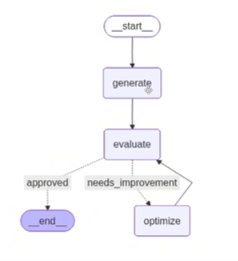

we need 3 LLMS One for Generation, second for evaluation, third for optimizing

In [44]:
llm_generation=ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=1.0
)

In [45]:
llm_evaluator=ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=1.0
)

In [46]:
llm_optimization=ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=1.0
)

In [47]:
from pydantic import BaseModel,Field

class PostEvaluation(BaseModel):
    evaluation:Literal["approved","needs_improvement"]=Field(...,description="Final evaluation Result")
    feedback:str=Field(...,description="feedback for facebook post")

In [48]:
structured_evaluator_llm=llm_evaluator.with_structured_output(PostEvaluation)

In [49]:
post="""Sometimes we get so focused on where we want to be that we forget to appreciate how far we've already come.

Not every day is about achieving something big. Some days, simply showing up, learning something new, fixing a mistake, or taking one small step forward is enough.

Progress doesn't always look impressive from the outside.

Keep going. Keep learning. Keep growing.

One day, you'll look back and realize that those small steps were actually taking you somewhere. ❤️

#Growth #Progress #KeepGoing
"""

In [50]:
result=structured_evaluator_llm.invoke(post)

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


In [51]:
result.evaluation,result.feedback

('approved',
 'The post is well-written, engaging, and delivers a positive, encouraging message that resonates well with the audience. The tone is supportive, and the use of formatting and hashtags is appropriate.')

functions for nodes

In [52]:
def generate_post(state: PostState):

    # prompt
    messages = [
        SystemMessage(content="You are a funny and clever Facebook influencer."),
        HumanMessage(content=f"""
Write a short, original, and hilarious Facebook post on the topic: "{state['topic']}".

Rules:
- Do NOT use question-answer format.
- Max 500 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
""")
    ]

    # send generator_llm
    response = llm_generation.invoke(messages).content

    # return response
    return {'post': response, 'post_history': [response]}

In [53]:
def evaluate_post(state: PostState):

    # prompt
    messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Facebook critic. You evaluate posts based on humor, originality, virality, and post format."),
    HumanMessage(content=f"""
Evaluate the following Facebook post:

Post: "{state['post']}"

Use the criteria below to evaluate the post:

1. Originality – Is this fresh, or have you seen it a hundred times before?  
2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
3. Punchiness – Is it short, sharp, and scroll-stopping?  
4. Virality Potential – Would people share, react, or comment on it?  
5. Format – Is it a well-formed Facebook post (not a setup-punchline joke, not a Q&A joke, and under 500 characters)?

Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 500 characters
- It reads like a traditional setup-punchline joke
- Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

### Respond ONLY in structured format:
- evaluation: "approved" or "needs_improvement"  
- feedback: One paragraph explaining the strengths and weaknesses 
""")
]

    response = structured_evaluator_llm.invoke(messages)

    return {'evaluation':response.evaluation, 'feedback': response.feedback, 'feedback_history': [response.feedback]}

In [54]:
def optimize_post(state: PostState):

    messages = [
        SystemMessage(content="You punch up Facebook posts for virality and humor based on given feedback."),
        HumanMessage(content=f"""
Improve the Facebook post based on this feedback:
"{state['feedback']}"

Topic: "{state['topic']}"
Original Post:
{state['post']}

Re-write it as a short, viral-worthy Facebook post. Avoid Q&A style and stay under 500 characters.
""")
    ]

    response = llm_optimization.invoke(messages).content
    iteration = state['iteration'] + 1     #storing iteration

    return {'post': response, 'iteration': iteration, 'post_history': [response]}

conditional function

In [55]:
def route_evaluation(state: PostState):

    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return 'needs_improvement'

defining graph

In [56]:
graph=StateGraph(PostState)

#add nodes
graph.add_node('generate',generate_post)
graph.add_node('evaluate',evaluate_post)
graph.add_node('optimize',optimize_post)

#add edges
graph.add_edge(START, 'generate')
graph.add_edge('generate', 'evaluate')
graph.add_conditional_edges('evaluate',route_evaluation,{'approved': END, 'needs_improvement': 'optimize'})
graph.add_edge('optimize', 'evaluate') #looping back [iteration]

workflow = graph.compile()

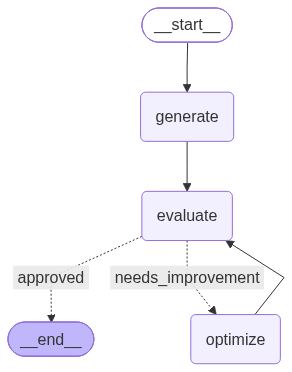

In [57]:
workflow

In [58]:
initial_state = {
    "topic": "Indian Stock Market after COVID",
    "iteration": 1,
    "max_iteration": 5
}
result = workflow.invoke(initial_state)

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


In [59]:
result

{'topic': 'Indian Stock Market after COVID',
 'post': [{'type': 'text',
   'text': 'Pre-COVID: "Beta, FD is safest. Mutual funds are jua (gambling)." \n\nPost-COVID: Every 22-year-old in India is suddenly Warren Buffett, trading options on their lunch break, analyzing candlestick charts while eating Maggi, and giving unsolicited Gyan on small-caps at family weddings. \n\nOne red day on Dalal Street and entire generation’s career plans instantly shift from "tech entrepreneur" back to "preparing for UPSC." 📉😂☕️',
   'extras': {'signature': 'El4KXAERTTIPhn4y66S/0X7gKbPypmD7beXSIuHSFXnEaSdzb40PbP2Aom+Vs+jOtZs7M6Ge4duV0WQ9gLZGPrlGWSfG+6lX1Gmck19HaomWrxUviWTR0nL1Z94nmiLX'}}],
 'evaluation': 'approved',
 'feedback': 'This post hits the nail on the head regarding the post-COVID retail trading boom in India with sharp cultural observations and great imagery like analyzing charts while eating Maggi. It avoids standard Q&A formats and traditional setup-punchline structures, keeping the pacing tig

In [60]:
for post in result['feedback_history']:
    print(post)

This post hits the nail on the head regarding the post-COVID retail trading boom in India with sharp cultural observations and great imagery like analyzing charts while eating Maggi. It avoids standard Q&A formats and traditional setup-punchline structures, keeping the pacing tight and highly relatable for a Facebook audience. The length stays within bounds and naturally lends itself to heavy shares and comments from the target demographic.
